In [1]:
!pip -q install pandas numpy networkx matplotlib seaborn scikit-learn plotly requests

In [2]:
import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully!")
print("Pandas:", pd.__version__)
print("NetworkX:", nx.__version__)

Libraries imported successfully!
Pandas: 2.2.3
NetworkX: 3.7


In [3]:
!pip -q install huggingface_hub

In [4]:
from huggingface_hub import hf_hub_download
import pickle

DATASET_REPO = "NunoBatista/PHEME-Misinformation-Graphs"

graph_file = hf_hub_download(
    repo_id=DATASET_REPO,
    filename="pheme_cascades.gpickle",
    repo_type="dataset"
)

print("Dataset downloaded to:", graph_file)

pheme_cascades.gpickle: reconstructing file:   0%|          |  0.00B /  193MB            

pheme_cascades.gpickle: downloading bytes:           |  0.00B            

Dataset downloaded to: /root/.cache/huggingface/hub/datasets--NunoBatista--PHEME-Misinformation-Graphs/snapshots/6683bbe5ed2d604b44a0272f44a9435b43f03553/pheme_cascades.gpickle


In [5]:
import pickle
import networkx as nx

with open(graph_file, "rb") as f:
    cascades = pickle.load(f)

print("Dataset loaded successfully!")
print("Total cascades:", len(cascades))

G = cascades[0]

print("\nFirst cascade type:", type(G))
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

print("\nGraph metadata:")
print(G.graph)

print("\nFirst 5 nodes:")
for node, attrs in list(G.nodes(data=True))[:5]:
    print(node, attrs)

print("\nFirst 5 edges:")
for edge in list(G.edges(data=True))[:5]:
    print(edge)

Dataset loaded successfully!
Total cascades: 6425

First cascade type: <class 'networkx.classes.digraph.DiGraph'>
Nodes: 27
Edges: 25

Graph metadata:
{'label': 1, 'thread_id': '500388199064420352', 'event': 'ferguson-all-rnr-threads'}

First 5 nodes:
500388199064420352 {'text': 'Hard to believe this guy assaulted a cop. 😂😂😂 \n\n#Ferguson http://t.co/J86VLXnZF6', 'user_followers': 19415, 'user_verified': 0, 'is_source': False, 'pagerank': 0.0266464358626877, 'degree_centrality': 0.5384615384615385, 'in_degree': 0.038461538461538464, 'out_degree': 0.5, 'text_embedding': array([-6.15523085e-02,  1.20465609e-03,  2.25249026e-02,  6.77943155e-02,
        9.27691683e-02,  5.21238483e-02,  9.18839648e-02,  1.38807213e-02,
       -1.96218002e-03,  5.52594326e-02,  8.62625241e-02,  3.31596471e-02,
        9.92505625e-03, -1.08170127e-02, -5.68560660e-02, -8.34024802e-04,
        3.28662023e-02,  1.91289559e-02, -3.21666971e-02,  1.59913320e-02,
       -3.10474564e-03, -1.41400099e-02,  3.67018

In [7]:
with open(graph_file, "rb") as f:
    cascades = pickle.load(f)

# Normalize common container formats into a list of graphs.
if isinstance(cascades, dict):
    graph_list = list(cascades.values())
elif isinstance(cascades, (list, tuple)):
    graph_list = list(cascades)
else:
    raise TypeError(f"Unexpected dataset type: {type(cascades)}")

graph_list = [
    g for g in graph_list
    if isinstance(g, (nx.Graph, nx.DiGraph, nx.MultiGraph, nx.MultiDiGraph))
]

print("Graphs loaded:", len(graph_list))
print("First graph:", type(graph_list[0]) if graph_list else "No graphs found")

Graphs loaded: 6425
First graph: <class 'networkx.classes.digraph.DiGraph'>


In [8]:
if not graph_list:
    raise ValueError("No NetworkX graphs found. Inspect the downloaded dataset format.")

G = graph_list[0]

print("Directed:", G.is_directed())
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("\nGraph-level attributes:")
print(G.graph)

print("\nFirst five nodes and attributes:")
for node, attrs in list(G.nodes(data=True))[:5]:
    print(node, attrs)

print("\nFirst five edges:")
for edge in list(G.edges(data=True))[:5]:
    print(edge)

Directed: True
Nodes: 27
Edges: 25

Graph-level attributes:
{'label': 1, 'thread_id': '500388199064420352', 'event': 'ferguson-all-rnr-threads'}

First five nodes and attributes:
500388199064420352 {'text': 'Hard to believe this guy assaulted a cop. 😂😂😂 \n\n#Ferguson http://t.co/J86VLXnZF6', 'user_followers': 19415, 'user_verified': 0, 'is_source': False, 'pagerank': 0.0266464358626877, 'degree_centrality': 0.5384615384615385, 'in_degree': 0.038461538461538464, 'out_degree': 0.5, 'text_embedding': array([-6.15523085e-02,  1.20465609e-03,  2.25249026e-02,  6.77943155e-02,
        9.27691683e-02,  5.21238483e-02,  9.18839648e-02,  1.38807213e-02,
       -1.96218002e-03,  5.52594326e-02,  8.62625241e-02,  3.31596471e-02,
        9.92505625e-03, -1.08170127e-02, -5.68560660e-02, -8.34024802e-04,
        3.28662023e-02,  1.91289559e-02, -3.21666971e-02,  1.59913320e-02,
       -3.10474564e-03, -1.41400099e-02,  3.67018059e-02,  1.62347853e-02,
       -9.93826240e-02,  8.10338631e-02, -3.882

In [9]:
def graph_depth(G):
    """Return longest shortest-path depth from a root when possible."""
    if G.number_of_nodes() == 0:
        return 0

    if not G.is_directed():
        H = G
    else:
        H = G

    roots = [n for n, d in H.in_degree() if d == 0] if H.is_directed() else []

    if roots:
        lengths = nx.single_source_shortest_path_length(H, roots[0])
        return max(lengths.values(), default=0)

    if nx.is_directed_acyclic_graph(H):
        return max(
            (len(path) - 1 for path in nx.all_simple_paths(
                H, source=list(H.nodes())[0], target=list(H.nodes())[-1]
            )),
            default=0
        )

    return -1  # No reliable tree depth calculated


def get_graph_label(G):
    """Read a graph-level rumour label if one exists."""
    possible_keys = ["label", "class", "rumour", "rumor", "is_rumour",
                     "is_rumor", "target", "y"]

    for key in possible_keys:
        if key in G.graph:
            value = G.graph[key]

            if isinstance(value, (bool, np.bool_)):
                return int(value)

            if isinstance(value, (int, np.integer)) and value in (0, 1):
                return int(value)

            if isinstance(value, str):
                value_lower = value.lower().strip()
                if value_lower in ["rumour", "rumor", "true", "yes", "1"]:
                    return 1
                if value_lower in ["non-rumour", "non-rumor", "false", "no", "0"]:
                    return 0

    return np.nan


def extract_graph_features(G, cascade_id):
    n = G.number_of_nodes()
    m = G.number_of_edges()

    if n == 0:
        return None

    # Convert undirected graphs to directed graphs for consistent processing.
    DG = G if G.is_directed() else G.to_directed()

    in_degrees = [d for _, d in DG.in_degree()]
    out_degrees = [d for _, d in DG.out_degree()]

    try:
        pagerank = nx.pagerank(DG, max_iter=100)
        pagerank_max = max(pagerank.values(), default=0)
        pagerank_mean = np.mean(list(pagerank.values())) if pagerank else 0
    except Exception:
        pagerank_max = 0
        pagerank_mean = 0

    try:
        undirected = DG.to_undirected()
        components = list(nx.connected_components(undirected))
        largest_component = max((len(c) for c in components), default=0)
    except Exception:
        largest_component = 0

    try:
        density = nx.density(DG)
    except Exception:
        density = 0

    try:
        depth = graph_depth(DG)
    except Exception:
        depth = -1

    return {
        "cascade_id": cascade_id,
        "nodes": n,
        "edges": m,
        "density": density,
        "mean_in_degree": float(np.mean(in_degrees)),
        "max_in_degree": max(in_degrees, default=0),
        "mean_out_degree": float(np.mean(out_degrees)),
        "max_out_degree": max(out_degrees, default=0),
        "pagerank_max": pagerank_max,
        "pagerank_mean": pagerank_mean,
        "largest_component_size": largest_component,
        "depth": depth,
        "label": get_graph_label(G)
    }


feature_rows = []

for i, graph in enumerate(graph_list):
    row = extract_graph_features(graph, i)
    if row is not None:
        feature_rows.append(row)

features_df = pd.DataFrame(feature_rows)

print("Feature table shape:", features_df.shape)
display(features_df.head())

Feature table shape: (6425, 13)


,cascade_id,nodes,edges,density,mean_in_degree,max_in_degree,mean_out_degree,max_out_degree,pagerank_max,pagerank_mean,largest_component_size,depth,label
0,0,27,25,0.035613,0.925926,1,0.925926,13,0.072247,0.037037,23,1,1
1,1,15,14,0.066667,0.933333,1,0.933333,11,0.104147,0.066667,15,3,1
2,2,16,15,0.062500,0.937500,1,0.937500,13,0.102115,0.062500,16,2,1
3,3,9,9,0.125000,1.000000,1,1.000000,7,0.211970,0.111111,9,-1,1
4,4,10,9,0.100000,0.900000,1,0.900000,8,0.164568,0.100000,10,2,1


In [10]:
print("Missing values per column:")
display(features_df.isna().sum().to_frame("missing_values"))

print("\nAvailable label values:")
print(features_df["label"].value_counts(dropna=False))

print("\nSummary statistics:")
display(features_df.describe().T)

Missing values per column:


,missing_values
cascade_id,0
nodes,0
edges,0
density,0
mean_in_degree,0
max_in_degree,0
mean_out_degree,0
max_out_degree,0
pagerank_max,0
pagerank_mean,0



Available label values:
label
0    4023
1    2402
Name: count, dtype: int64

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
cascade_id,6425.0,3212.000000,1854.882072,0.000000,1606.000000,3212.000000,4818.000000,6424.0
nodes,6425.0,16.458677,19.790203,1.000000,5.000000,12.000000,21.000000,346.0
edges,6425.0,15.397510,19.611731,0.000000,4.000000,11.000000,20.000000,345.0
density,6425.0,0.105346,0.121263,0.000000,0.038333,0.058824,0.125000,1.0
mean_in_degree,6425.0,0.793540,0.294851,0.000000,0.800000,0.916667,0.954545,1.0
max_in_degree,6425.0,0.894630,0.307053,0.000000,1.000000,1.000000,1.000000,1.0
mean_out_degree,6425.0,0.793540,0.294851,0.000000,0.800000,0.916667,0.954545,1.0
max_out_degree,6425.0,8.548171,6.429319,0.000000,3.000000,8.000000,13.000000,123.0
pagerank_max,6425.0,0.248205,0.288266,0.006401,0.084504,0.124110,0.250000,1.0
pagerank_mean,6425.0,0.208904,0.292553,0.002890,0.047619,0.083333,0.200000,1.0


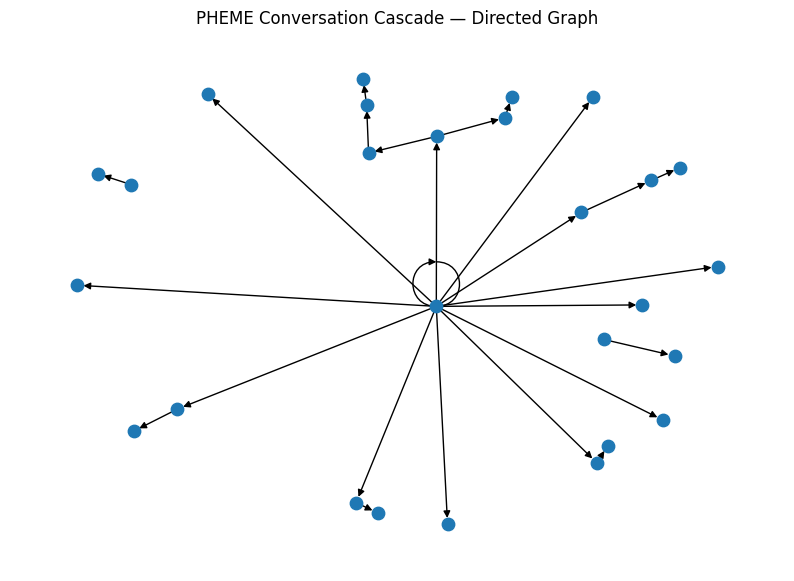

In [11]:
G = graph_list[0]

plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G, seed=RANDOM_STATE)

nx.draw_networkx(
    G,
    pos=pos,
    node_size=80,
    font_size=6,
    arrows=G.is_directed(),
    with_labels=False
)

plt.title("PHEME Conversation Cascade — Directed Graph")
plt.axis("off")
plt.show()

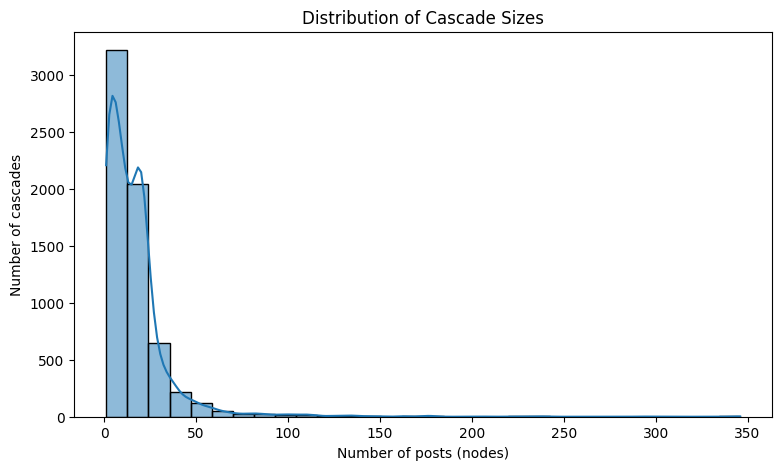

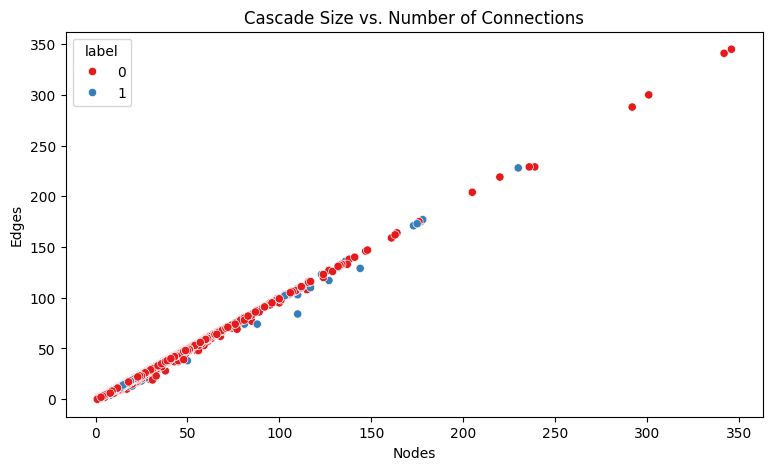

In [12]:
plt.figure(figsize=(9, 5))
sns.histplot(features_df["nodes"], bins=30, kde=True)
plt.title("Distribution of Cascade Sizes")
plt.xlabel("Number of posts (nodes)")
plt.ylabel("Number of cascades")
plt.show()

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=features_df,
    x="nodes",
    y="edges",
    hue="label",
    palette="Set1",
    legend="full"
)
plt.title("Cascade Size vs. Number of Connections")
plt.xlabel("Nodes")
plt.ylabel("Edges")
plt.show()

In [13]:
TIMESTAMP_KEYS = [
    "timestamp", "created_at", "createdAt", "time", "date",
    "created", "publish_time"
]

def parse_timestamp(value):
    if value is None:
        return pd.NaT

    try:
        if isinstance(value, (int, float, np.integer, np.floating)):
            # Handle Unix timestamps in seconds or milliseconds.
            value = float(value)
            if value > 1e12:
                value /= 1000
            return pd.to_datetime(value, unit="s", utc=True, errors="coerce")

        return pd.to_datetime(value, utc=True, errors="coerce")
    except Exception:
        return pd.NaT


def get_node_timestamp(attrs):
    for key in TIMESTAMP_KEYS:
        if key in attrs:
            ts = parse_timestamp(attrs[key])
            if pd.notna(ts):
                return ts
    return pd.NaT


def make_replay_events(G, cascade_id):
    DG = G if G.is_directed() else G.to_directed()
    rows = []

    # Prefer actual timestamps from node attributes.
    for node, attrs in DG.nodes(data=True):
        ts = get_node_timestamp(attrs)
        rows.append({
            "cascade_id": cascade_id,
            "node_id": str(node),
            "timestamp": ts,
            "actual_timestamp": pd.notna(ts)
        })

    events = pd.DataFrame(rows)

    # If no timestamps are present, simulate relative times from graph distance.
    if events.empty:
        return events

    if events["timestamp"].notna().sum() == 0:
        roots = [n for n, d in DG.in_degree() if d == 0]

        if roots:
            root = roots[0]
            distances = nx.single_source_shortest_path_length(DG, root)
        else:
            root = list(DG.nodes())[0]
            distances = nx.single_source_shortest_path_length(
                DG.to_undirected(), root
            )

        base = pd.Timestamp("2026-01-01T00:00:00Z")
        simulated_times = []

        for node in DG.nodes():
            distance = distances.get(node, 0)
            # Add small deterministic offsets to separate posts at the same depth.
            offset_seconds = int(distance * 60 + (abs(hash(str(node))) % 50))
            simulated_times.append(base + pd.Timedelta(seconds=offset_seconds))

        events["timestamp"] = simulated_times
        events["actual_timestamp"] = False

    else:
        # Do not silently fabricate missing timestamps within a partially timestamped graph.
        events = events.dropna(subset=["timestamp"])

    return events.sort_values("timestamp").reset_index(drop=True)


replay_graph_id = 0
replay_events = make_replay_events(
    graph_list[replay_graph_id],
    replay_graph_id
)

print("Replay events:", len(replay_events))
print("Using actual timestamps:", replay_events["actual_timestamp"].all())
display(replay_events.head(10))

Replay events: 27
Using actual timestamps: False


,cascade_id,node_id,timestamp,actual_timestamp
0,0,500477269404823553,2026-01-01 00:00:00+00:00,False
1,0,500389128442511361,2026-01-01 00:00:01+00:00,False
2,0,500395122404896768,2026-01-01 00:00:02+00:00,False
3,0,500389123560341504,2026-01-01 00:00:06+00:00,False
4,0,500391412526235648,2026-01-01 00:00:11+00:00,False
5,0,500389257299918848,2026-01-01 00:00:12+00:00,False
6,0,500390750740578305,2026-01-01 00:00:15+00:00,False
7,0,500392731391582208,2026-01-01 00:00:16+00:00,False
8,0,500388648408600576,2026-01-01 00:00:16+00:00,False
9,0,500391591777804288,2026-01-01 00:00:17+00:00,False


In [14]:
if replay_events.empty:
    raise ValueError("No replay events available for the selected cascade.")

replay_events["time_bin"] = replay_events["timestamp"].dt.floor("1min")

wave_df = (
    replay_events.groupby("time_bin")
    .size()
    .rename("new_posts")
    .reset_index()
    .sort_values("time_bin")
)

wave_df["cumulative_posts"] = wave_df["new_posts"].cumsum()
wave_df["velocity"] = wave_df["new_posts"]  # posts per one-minute interval
wave_df["acceleration"] = wave_df["velocity"].diff().fillna(0)

peak_row = wave_df.loc[wave_df["new_posts"].idxmax()]

print("Peak interval:", peak_row["time_bin"])
print("Posts in peak interval:", peak_row["new_posts"])
print("Total replayed posts:", int(wave_df["new_posts"].sum()))

display(wave_df.head(10))

Peak interval: 2026-01-01 00:00:00+00:00
Posts in peak interval: 26
Total replayed posts: 27


,time_bin,new_posts,cumulative_posts,velocity,acceleration
0,2026-01-01 00:00:00+00:00,26,26,26,0.0
1,2026-01-01 00:01:00+00:00,1,27,1,-25.0


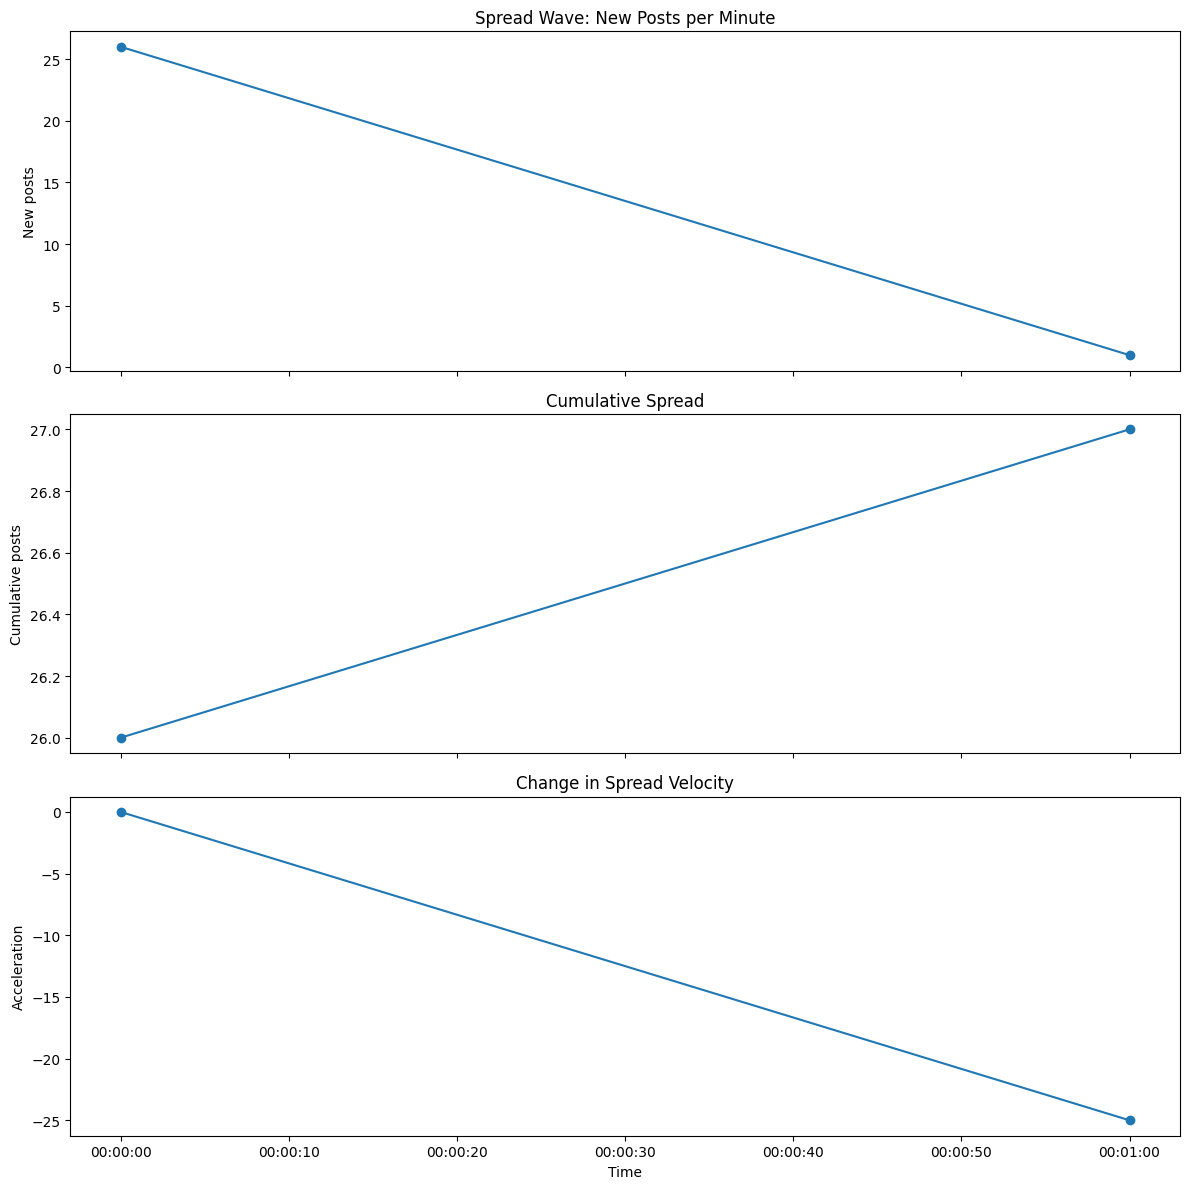

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

axes[0].plot(wave_df["time_bin"], wave_df["new_posts"], marker="o")
axes[0].set_title("Spread Wave: New Posts per Minute")
axes[0].set_ylabel("New posts")

axes[1].plot(wave_df["time_bin"], wave_df["cumulative_posts"], marker="o")
axes[1].set_title("Cumulative Spread")
axes[1].set_ylabel("Cumulative posts")

axes[2].plot(wave_df["time_bin"], wave_df["acceleration"], marker="o")
axes[2].set_title("Change in Spread Velocity")
axes[2].set_ylabel("Acceleration")
axes[2].set_xlabel("Time")

plt.tight_layout()
plt.show()

In [16]:
PLAY_DELAY_SECONDS = 0  # Change to 0.2 or 0.5 for a slower demonstration
MAX_EVENTS_TO_DISPLAY = 30

print("Starting historical/synthetic replay...")
print("Timestamp source:",
      "actual" if replay_events["actual_timestamp"].all() else "synthetic or mixed")

for _, event in replay_events.head(MAX_EVENTS_TO_DISPLAY).iterrows():
    print(
        f"{event['timestamp']} | "
        f"Cascade: {event['cascade_id']} | "
        f"Post: {event['node_id']}"
    )

    if PLAY_DELAY_SECONDS > 0:
        time.sleep(PLAY_DELAY_SECONDS)

print("Replay completed.")

Starting historical/synthetic replay...
Timestamp source: synthetic or mixed
2026-01-01 00:00:00+00:00 | Cascade: 0 | Post: 500477269404823553
2026-01-01 00:00:01+00:00 | Cascade: 0 | Post: 500389128442511361
2026-01-01 00:00:02+00:00 | Cascade: 0 | Post: 500395122404896768
2026-01-01 00:00:06+00:00 | Cascade: 0 | Post: 500389123560341504
2026-01-01 00:00:11+00:00 | Cascade: 0 | Post: 500391412526235648
2026-01-01 00:00:12+00:00 | Cascade: 0 | Post: 500389257299918848
2026-01-01 00:00:15+00:00 | Cascade: 0 | Post: 500390750740578305
2026-01-01 00:00:16+00:00 | Cascade: 0 | Post: 500392731391582208
2026-01-01 00:00:16+00:00 | Cascade: 0 | Post: 500388648408600576
2026-01-01 00:00:17+00:00 | Cascade: 0 | Post: 500391591777804288
2026-01-01 00:00:19+00:00 | Cascade: 0 | Post: 500389859937497088
2026-01-01 00:00:20+00:00 | Cascade: 0 | Post: 500389600003493888
2026-01-01 00:00:22+00:00 | Cascade: 0 | Post: 500388199064420352
2026-01-01 00:00:24+00:00 | Cascade: 0 | Post: 500473211684134913

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Required machine learning imports completed!")

Required machine learning imports completed!


In [19]:
feature_columns = [
    "nodes",
    "edges",
    "density",
    "mean_in_degree",
    "max_in_degree",
    "mean_out_degree",
    "max_out_degree",
    "pagerank_max",
    "pagerank_mean",
    "largest_component_size",
    "depth"
]

ml_df = features_df.dropna(subset=["label"]).copy()
ml_df = ml_df[ml_df["label"].isin([0, 1])].copy()

if ml_df.empty:
    raise ValueError(
        "No usable labels found. Inspect G.graph and the dataset's label mapping "
        "before proceeding with supervised learning."
    )

if ml_df["label"].nunique() < 2:
    raise ValueError(
        "Only one label class was found. Verify the dataset labels before training."
    )

X = ml_df[feature_columns].replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True)).fillna(0)
y = ml_df["label"].astype(int)

# Use a cascade-level split: each cascade is one independent example.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Training examples: 5140
Testing examples: 1285
Accuracy: 0.5471

Classification report:
              precision    recall  f1-score   support

           0       0.68      0.52      0.59       805
           1       0.42      0.59      0.49       480

    accuracy                           0.55      1285
   macro avg       0.55      0.56      0.54      1285
weighted avg       0.58      0.55      0.55      1285



In [20]:
feature_columns = [
    "nodes",
    "edges",
    "density",
    "mean_in_degree",
    "max_in_degree",
    "mean_out_degree",
    "max_out_degree",
    "pagerank_max",
    "pagerank_mean",
    "largest_component_size",
    "depth"
]

ml_df = features_df.dropna(subset=["label"]).copy()
ml_df = ml_df[ml_df["label"].isin([0, 1])].copy()

if ml_df.empty:
    raise ValueError(
        "No usable labels found. Inspect G.graph and the dataset's label mapping "
        "before proceeding with supervised learning."
    )

if ml_df["label"].nunique() < 2:
    raise ValueError(
        "Only one label class was found. Verify the dataset labels before training."
    )

X = ml_df[feature_columns].replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True)).fillna(0)
y = ml_df["label"].astype(int)

# Use a cascade-level split: each cascade is one independent example.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Training examples: 5140
Testing examples: 1285
Accuracy: 0.5471

Classification report:
              precision    recall  f1-score   support

           0       0.68      0.52      0.59       805
           1       0.42      0.59      0.49       480

    accuracy                           0.55      1285
   macro avg       0.55      0.56      0.54      1285
weighted avg       0.58      0.55      0.55      1285



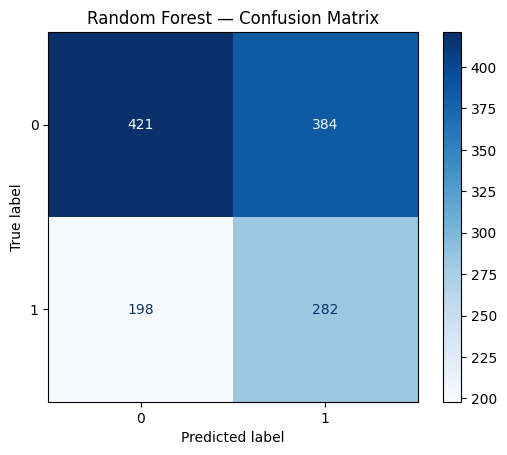

In [21]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    values_format="d"
)
plt.title("Random Forest — Confusion Matrix")
plt.show()

,feature,importance
7,pagerank_max,0.329007
6,max_out_degree,0.189774
10,depth,0.120418
9,largest_component_size,0.061280
3,mean_in_degree,0.056721
5,mean_out_degree,0.055292
2,density,0.051153
8,pagerank_mean,0.047696
1,edges,0.045753
0,nodes,0.042828


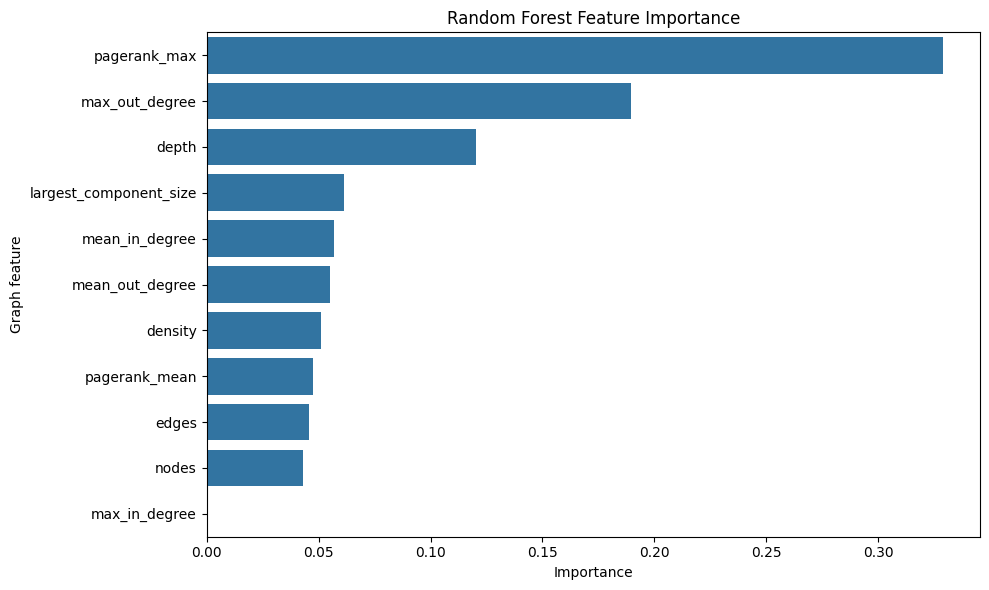

In [22]:
importance_df = pd.DataFrame({
    "feature": feature_columns,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="importance", y="feature")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Graph feature")
plt.tight_layout()
plt.show()

In [24]:
import plotly.express as px

print("Plotly Express imported successfully!")

Plotly Express imported successfully!


In [25]:
fig = px.line(
    wave_df,
    x="time_bin",
    y=["new_posts", "cumulative_posts"],
    markers=True,
    title="Interactive Misinformation Spread-Wave Analysis",
    labels={
        "time_bin": "Time",
        "value": "Number of posts",
        "variable": "Metric"
    }
)

fig.show()

In [26]:
OUTPUT_DIR = Path("/content/misinformation_project_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

features_df.to_csv(
    OUTPUT_DIR / "graph_features.csv",
    index=False
)

replay_events.to_csv(
    OUTPUT_DIR / "replay_events.csv",
    index=False
)

wave_df.to_csv(
    OUTPUT_DIR / "spread_wave_analysis.csv",
    index=False
)

importance_df.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False
)

if "model" in globals() and "X_test" in globals():
    prediction_df = X_test.copy()
    prediction_df["actual_label"] = y_test
    prediction_df["predicted_label"] = y_pred
    prediction_df.to_csv(
        OUTPUT_DIR / "model_predictions.csv",
        index=True
    )

print("Results saved to:", OUTPUT_DIR)
print("Files:", [p.name for p in OUTPUT_DIR.iterdir()])

Results saved to: /content/misinformation_project_outputs
Files: ['feature_importance.csv', 'spread_wave_analysis.csv', 'replay_events.csv', 'graph_features.csv', 'model_predictions.csv']


In [27]:
from google.colab import files

files.download(
    "/content/misinformation_project_outputs/graph_features.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import os

print("Notebook outputs:")
for file in os.listdir("/content/misinformation_project_outputs"):
    print(file)

Notebook outputs:
feature_importance.csv
spread_wave_analysis.csv
replay_events.csv
graph_features.csv
model_predictions.csv
